# 07 Three ways to control for video age

In [1]:
"""Three ways to take video age out of engagement:
1. one universal growth curve from the daily log (daily breakpoints to day 30, smoothed),
2. a curve per channel: the universal curve sped up or slowed down by a channel factor k, learned from the daily log,
3. views observed at a fixed age (3, 7, 14, 30, 60, 90 days), no curve.
Metric 1 (what normalization is for): project a video's views from one snapshot at age s to age s + HORIZON and
compare with what it actually got. Metric 2 (explainability): what the 79 traits add to a within-channel model of
age-free views, real vs shuffled traits. The Oct 15 snapshot (6 days before daily logging began) is included."""
import os
import sys
import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from google.cloud import bigquery
from matplotlib.colors import LinearSegmentedColormap
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, os.path.abspath("../src"))
import config
from traits import get_traits

warnings.filterwarnings("ignore")

FIRST_SNAPSHOT = "2026-10-15"
DAILY_START = "2026-10-21"
SNAPSHOT_DATE = "2026-11-12"
REF_AGE = 30
FIXED_AGES = [3, 7, 14, 30, 60, 90]
START_AGES = [1, 2, 3, 5, 7, 10, 14, 21, 30, 60, 90, 180]
HORIZON = 14
MAX_BRACKET_DAYS = 1.5
KNOTS = np.array(list(range(1, 31)) + [35, 40, 45, 52, 60, 70, 80, 90, 105, 120, 140, 160, 180, 210, 240, 270, 300, 340, 400], dtype=float)
SMOOTHING_GRID = [0, 0.01, 0.1, 1, 10, 100, 1000]
SHRINK_GRID = [0, 0.1, 0.3, 1, 3, 10, 30, 100]
SHORTS_MAX_SECONDS = 60
N_FOLDS = 5
N_REPEATS = 3
N_SHUFFLES = 10
ALPHAS = np.logspace(-2, 4, 25)
SEED = 585
RED, BAR, GRAY, DARK, MUTED = "#990000", "#C0392B", "#BDBDBD", "#222222", "#6B6B6B"
FIG_DIR = "../docs/figures"
ANALYSIS_DIR = "../data/analysis"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(ANALYSIS_DIR, exist_ok=True)
plt.rcParams.update({"font.family": "Arial", "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#888888", "axes.labelcolor": "#444444", "xtick.color": "#555555", "ytick.color": "#555555"})
rng = np.random.default_rng(SEED)
client = bigquery.Client(project=config.GCP_PROJECT_ID, location=config.BQ_LOCATION)

## Load the snapshots and the tagged videos

In [2]:
"""Every snapshot of every video on the sheet's channels, Oct 15 (one-time pull) and daily from Oct 21."""
df_panel = client.query(f"""
SELECT s.video_id, s.channel_id, c.snippet_title AS channel_title, s.snapshot_date, s.snapshot_at, s.age_days, s.view_count,
       v.duration_seconds
FROM youtube.video_daily_snapshots s
JOIN youtube.videos v ON v.id = s.video_id
JOIN youtube.channels c ON c.id = s.channel_id
WHERE s.snapshot_date BETWEEN '{FIRST_SNAPSHOT}' AND '{SNAPSHOT_DATE}' AND s.is_available
""").to_dataframe().sort_values(["video_id", "snapshot_at"]).reset_index(drop=True)
df_panel["lv"] = np.log1p(df_panel["view_count"].astype(float))
print(f"{len(df_panel):,} snapshot rows, {df_panel['video_id'].nunique():,} videos; "
      f"{(df_panel['snapshot_date'].astype(str) == FIRST_SNAPSHOT).sum():,} from {FIRST_SNAPSHOT}")

310,958 snapshot rows, 14,030 videos; 12,024 from 2026-10-15


In [3]:
"""Tagged videos on the current channel list, with metadata and their views on SNAPSHOT_DATE.
The duplicate tagging of one video keeps its earliest row."""
traits = get_traits()
trait_columns = [trait["column"] for trait in traits]
df_videos = client.query(f"""
WITH tagged AS (SELECT * EXCEPT(tag_rank) FROM (SELECT *, ROW_NUMBER() OVER (PARTITION BY id ORDER BY tagged_at) AS tag_rank
                                                FROM youtube.llm_tagged) WHERE tag_rank = 1)
SELECT {", ".join("t." + column for column in trait_columns)}, t.id, v.snippet_channelId AS channel_id,
       v.snippet_publishedAt AS published_at, v.snippet_title AS title, v.snippet_description AS description,
       v.snippet_tags AS tags, v.duration_seconds, v.contentDetails_caption AS caption,
       v.paidProductPlacementDetails_hasPaidProductPlacement AS paid_placement, s.age_days, s.view_count
FROM tagged t
JOIN youtube.videos v ON v.id = t.id
JOIN youtube.channels c ON c.id = v.snippet_channelId
JOIN youtube.video_daily_snapshots s ON s.video_id = t.id AND s.snapshot_date = '{SNAPSHOT_DATE}'
WHERE s.is_available AND s.view_count > 0 AND s.age_days >= 1
ORDER BY t.id""").to_dataframe().dropna(subset=trait_columns).reset_index(drop=True)
df_videos[trait_columns] = df_videos[trait_columns].astype(float)
df_videos["lv"] = np.log1p(df_videos["view_count"].astype(float))
trait_columns = [column for column in trait_columns if df_videos[column].std() > 0]
print(f"{len(df_videos):,} tagged videos, {df_videos['channel_id'].nunique()} channels, {len(trait_columns)} traits")

published_local = df_videos["published_at"].dt.tz_convert("America/Los_Angeles")
df_meta = pd.DataFrame({
    "log_duration": np.log1p(df_videos["duration_seconds"].astype(float)),
    "hour_sin": np.sin(2 * np.pi * published_local.dt.hour / 24),
    "hour_cos": np.cos(2 * np.pi * published_local.dt.hour / 24),
    "title_length": df_videos["title"].fillna("").str.len(),
    "description_length": np.log1p(df_videos["description"].fillna("").str.len()),
    "n_tags": df_videos["tags"].fillna("").apply(lambda tags: len([tag for tag in tags.split("|") if tag])),
    "has_caption": (df_videos["caption"] == "true").astype(float),
    "paid_placement": df_videos["paid_placement"].fillna(False).astype(float),
    "short": (df_videos["duration_seconds"] <= SHORTS_MAX_SECONDS).astype(float),
})
df_meta = pd.concat([df_meta, pd.get_dummies(published_local.dt.day_name(), prefix="weekday", drop_first=True, dtype=float)], axis=1)
df_channel = pd.get_dummies(df_videos["channel_id"], prefix="channel", drop_first=True, dtype=float)
X_traits = df_videos[trait_columns]
base_columns = pd.concat([df_meta, df_channel], axis=1)
all_rows = np.arange(len(df_videos))

3,021 tagged videos, 51 channels, 79 traits


## What snapshot data exists at each age

tagged   untagged  tagged  tagged_share
age_day                                
1              89     758          0.89
3              84     761          0.90
7              89     775          0.90
14             83     752          0.90
30            188     614          0.77
60            475     322          0.40
90            641     160          0.20
180           832      59          0.07
300           659      35          0.05


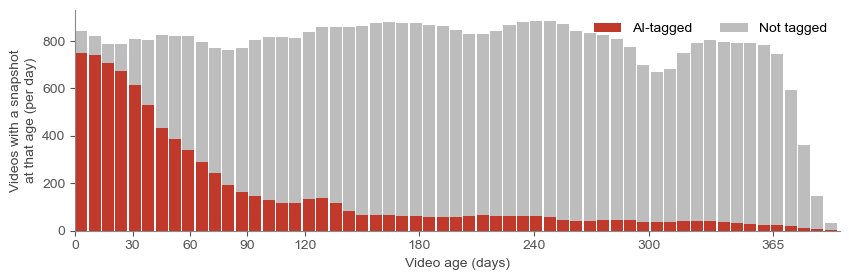

In [4]:
"""For each age in whole days, how many videos have a snapshot taken at that age, split by tagged. Weekly bins,
shown as the average count per day of age. Each video adds one count per day it was logged, at its age that day."""
tagged_ids = df_videos["id"].tolist()
df_panel["tagged"] = df_panel["video_id"].isin(tagged_ids)
df_panel["age_day"] = np.floor(df_panel["age_days"]).astype(int)
df_age_counts = df_panel.groupby(["age_day", "tagged"]).size().unstack(fill_value=0).rename(columns={False: "untagged", True: "tagged"})
df_age_counts = df_age_counts.reindex(range(0, df_age_counts.index.max() + 1), fill_value=0)
df_age_week = df_age_counts.groupby(df_age_counts.index // 7).mean()
df_age_week.index = df_age_week.index * 7
df_age_counts["tagged_share"] = df_age_counts["tagged"] / (df_age_counts["tagged"] + df_age_counts["untagged"])
print(df_age_counts.loc[[1, 3, 7, 14, 30, 60, 90, 180, 300]].round(2))

fig, ax = plt.subplots(figsize=(8.6, 2.9))
ax.bar(df_age_week.index, df_age_week["tagged"], width=6.3, align="edge", color=BAR, label="AI-tagged")
ax.bar(df_age_week.index, df_age_week["untagged"], width=6.3, align="edge", bottom=df_age_week["tagged"], color=GRAY, label="Not tagged")
ax.set_xlim(0, 400)
ax.set_xticks([0, 30, 60, 90, 120, 180, 240, 300, 365])
ax.set_xlabel("Video age (days)")
ax.set_ylabel("Videos with a snapshot\nat that age (per day)")
ax.legend(frameon=False, loc="upper right", ncol=2)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/age_data_availability.png", dpi=200)
plt.show()

## Day-to-day pairs and the curve fit

In [5]:
def basis(ages):
    """Linear-interpolation weights of each age on KNOTS, without the day-1 column (G(1) = 0 by definition)."""
    ages = np.clip(np.asarray(ages, dtype=float), KNOTS[0], KNOTS[-1])
    upper = np.clip(np.searchsorted(KNOTS, ages, side="right"), 1, len(KNOTS) - 1)
    weight = (ages - KNOTS[upper - 1]) / (KNOTS[upper] - KNOTS[upper - 1])
    out = np.zeros((len(ages), len(KNOTS)))
    out[np.arange(len(ages)), upper - 1] = 1 - weight
    out[np.arange(len(ages)), upper] = weight
    return out[:, 1:]


"""Smoothness penalty: the curve's slope against log(age) may change only gradually from one stretch to the next.
Rows of PENALTY act on the knot values (day-1 knot dropped, since G(1) = 0)."""
log_knots = np.log(KNOTS)
slope_rows = np.zeros((len(KNOTS) - 1, len(KNOTS)))
for knot_number in range(len(KNOTS) - 1):
    slope_rows[knot_number, knot_number] = -1 / (log_knots[knot_number + 1] - log_knots[knot_number])
    slope_rows[knot_number, knot_number + 1] = 1 / (log_knots[knot_number + 1] - log_knots[knot_number])
PENALTY = (slope_rows[1:] - slope_rows[:-1])[:, 1:]


def fit_curve(pair_basis, pair_growth, smoothing):
    """Penalized least squares for the knot values: each pair's log growth = G(age 2) - G(age 1)."""
    scale = np.sqrt(len(pair_growth))
    X = np.vstack([pair_basis, np.sqrt(smoothing) * scale * PENALTY])
    y = np.concatenate([pair_growth, np.zeros(len(PENALTY))])
    return np.linalg.lstsq(X, y, rcond=None)[0]


"""Pairs: consecutive snapshots of the same video, any gap (the Oct 15 -> Oct 21 gap of 6 days included), starting
at age >= 1 day and above 0 views."""
df_panel["lv_prev"] = df_panel.groupby("video_id")["lv"].shift()
df_panel["age_prev"] = df_panel.groupby("video_id")["age_days"].shift()
df_pairs = df_panel[(df_panel["lv_prev"] > 0) & (df_panel["age_prev"] >= 1)].reset_index(drop=True)
pair_basis = basis(df_pairs["age_days"]) - basis(df_pairs["age_prev"])
pair_growth = (df_pairs["lv"] - df_pairs["lv_prev"]).to_numpy()
pair_videos = df_pairs["video_id"].to_numpy()
pair_channels = df_pairs["channel_id"].to_numpy()
print(f"{len(df_pairs):,} pairs from {df_pairs['video_id'].nunique():,} videos; "
      f"{(df_pairs['age_days'] - df_pairs['age_prev'] > 2).sum():,} span the Oct 15 -> Oct 21 gap")

296,061 pairs from 13,937 videos; 25,817 span the Oct 15 -> Oct 21 gap


In [6]:
"""Choose the smoothing strength and the channel shrinkage by predicting held-out videos' day-to-day growth
(5 folds by video). Option 2's factor per channel: k = (sum x*y + m) / (sum x^2 + m), x = curve growth over the pair,
y = actual growth; m pulls channels with little data toward k = 1."""
video_ids = np.unique(pair_videos)
video_fold = dict(zip(video_ids, rng.permutation(len(video_ids)) % N_FOLDS))
pair_fold = np.array([video_fold[video_id] for video_id in pair_videos])


def channel_factors(curve_growth, growth, channels, shrink):
    df_k = pd.DataFrame({"channel": channels, "xy": curve_growth * growth, "xx": curve_growth ** 2}).groupby("channel").sum()
    return ((df_k["xy"] + shrink) / (df_k["xx"] + shrink)).to_dict()


smoothing_rows = []
for smoothing in SMOOTHING_GRID:
    squared_errors = np.zeros(len(pair_growth))
    for fold in range(N_FOLDS):
        train = pair_fold != fold
        knots_fold = fit_curve(pair_basis[train], pair_growth[train], smoothing)
        squared_errors[~train] = (pair_basis[~train] @ knots_fold - pair_growth[~train]) ** 2
    smoothing_rows.append({"smoothing": smoothing, "mse": squared_errors.mean()})
df_smoothing = pd.DataFrame(smoothing_rows)
best_smoothing = df_smoothing.loc[df_smoothing["mse"].idxmin(), "smoothing"]
print(df_smoothing.to_string(index=False), "\nchosen smoothing:", best_smoothing)

knot_values = fit_curve(pair_basis, pair_growth, best_smoothing)
shrink_rows = []
for shrink in SHRINK_GRID:
    squared_errors = np.zeros(len(pair_growth))
    for fold in range(N_FOLDS):
        train = pair_fold != fold
        knots_fold = fit_curve(pair_basis[train], pair_growth[train], best_smoothing)
        factors = channel_factors(pair_basis[train] @ knots_fold, pair_growth[train], pair_channels[train], shrink)
        k_test = np.array([factors.get(channel, 1.0) for channel in pair_channels[~train]])
        squared_errors[~train] = (k_test * (pair_basis[~train] @ knots_fold) - pair_growth[~train]) ** 2
    shrink_rows.append({"shrink": shrink, "mse": squared_errors.mean()})
df_shrink = pd.DataFrame(shrink_rows)
best_shrink = df_shrink.loc[df_shrink["mse"].idxmin(), "shrink"]
print(df_shrink.to_string(index=False), "\nchosen shrinkage:", best_shrink)

 smoothing      mse
      0.00 0.000151
      0.01 0.000162
      0.10 0.000173
      1.00 0.000175
     10.00 0.000175
    100.00 0.000175
   1000.00 0.000175 
chosen smoothing: 0.0


 shrink      mse
    0.0 0.000141
    0.1 0.000140
    0.3 0.000141
    1.0 0.000142
    3.0 0.000144
   10.0 0.000147
   30.0 0.000149
  100.0 0.000151 
chosen shrinkage: 0.1


In [7]:
"""Final curves on all pairs: the universal curve, and each channel's factor k."""
def G(ages, knots=knot_values):
    return basis(ages) @ knots


channel_k = channel_factors(pair_basis @ knot_values, pair_growth, pair_channels, best_shrink)
df_curve = pd.DataFrame({"age_days": KNOTS, "G": np.concatenate([[0.0], knot_values])})
df_curve["multiple_of_day1"] = np.exp(df_curve["G"])
df_curve["step_multiple"] = np.exp(df_curve["G"].diff().fillna(0))
df_curve.to_csv(f"{ANALYSIS_DIR}/age_universal_curve.csv", index=False)
print(df_curve[df_curve["age_days"].isin([1, 2, 3, 4, 5, 7, 10, 14, 21, 30, 60, 90, 180, 400])].round(3).to_string(index=False))

channel_titles = df_panel.drop_duplicates("channel_id").set_index("channel_id")["channel_title"]
df_k = pd.DataFrame({"channel_id": list(channel_k.keys()), "k": list(channel_k.values())})
df_k["channel"] = df_k["channel_id"].map(channel_titles)
df_k["pairs"] = df_k["channel_id"].map(df_pairs["channel_id"].value_counts())
df_k["young_pairs"] = df_k["channel_id"].map(df_pairs[df_pairs["age_prev"] < 30]["channel_id"].value_counts()).fillna(0).astype(int)
df_k = df_k.sort_values("k").reset_index(drop=True)
df_k.to_csv(f"{ANALYSIS_DIR}/age_channel_factors.csv", index=False)
print(df_k[["channel", "k", "pairs", "young_pairs"]].round(2).to_string(index=False))

 age_days     G  multiple_of_day1  step_multiple
      1.0 0.000             1.000          1.000
      2.0 0.271             1.311          1.311
      3.0 0.397             1.488          1.135
      4.0 0.488             1.629          1.095
      5.0 0.548             1.730          1.062
      7.0 0.631             1.879          1.038
     10.0 0.690             1.994          1.015
     14.0 0.733             2.082          1.008
     21.0 0.784             2.190          1.007
     30.0 0.831             2.296          1.005
     60.0 0.906             2.474          1.015
     90.0 0.950             2.586          1.013
    180.0 1.062             2.893          1.020
    400.0 1.200             3.319          1.030
                        channel    k  pairs  young_pairs
                       THE RACE 0.44  15799         1094
               Brodie Robertson 0.51   7424          547
               Club 520 Podcast 0.72  35632         2550
                   ShortCircuit 0.76 

## Option 3 values: views at a fixed age

 age  videos_observed  tagged uploaded_from uploaded_to
   3              815     734    2026-10-12  2026-11-09
   7              951     856    2026-10-08  2026-11-05
  14              988     890    2026-10-01  2026-10-29
  30              970     733    2026-09-15  2026-10-13
  60              996     380    2026-08-16  2026-09-13
  90              978     190    2026-07-17  2026-08-14


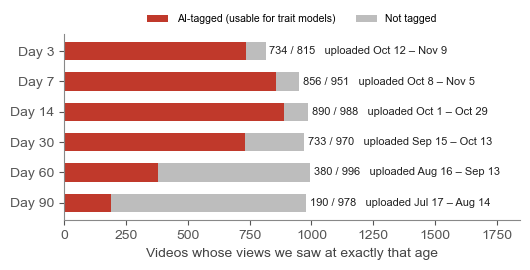

In [8]:
def value_at(df_video, age):
    """Log views at an exact age. Between snapshots at most MAX_BRACKET_DAYS apart: straight line. Across a longer
    gap (Oct 15 -> Oct 21): along the universal curve's shape. None if the age is not bracketed."""
    ages = df_video["age_days"].to_numpy()
    values = df_video["lv"].to_numpy()
    if not ages.min() <= age <= ages.max():
        return None, None
    after = np.searchsorted(ages, age)
    after = min(max(after, 1), len(ages) - 1)
    age_1, age_2, value_1, value_2 = ages[after - 1], ages[after], values[after - 1], values[after]
    if age_2 - age_1 <= MAX_BRACKET_DAYS:
        return value_1 + (value_2 - value_1) * (age - age_1) / (age_2 - age_1), True
    curve_span = G([age_2])[0] - G([max(age_1, 1)])[0]
    share = (G([age])[0] - G([max(age_1, 1)])[0]) / curve_span if curve_span > 0 else 0.5
    return value_1 + (value_2 - value_1) * share, False


all_ages = sorted(set(FIXED_AGES + START_AGES + [start_age + HORIZON for start_age in START_AGES]))
value_rows = []
for video_id, df_video in df_panel.groupby("video_id"):
    row = {"id": video_id, "channel_id": df_video["channel_id"].iloc[0]}
    for age in all_ages:
        value, direct = value_at(df_video, age)
        row[f"lv_{age}"] = value
        row[f"direct_{age}"] = direct
    value_rows.append(row)
df_values = pd.DataFrame(value_rows)
df_videos = df_videos.merge(df_values[["id"] + [f"lv_{age}" for age in FIXED_AGES]], on="id", how="left")
df_fixed_counts = pd.DataFrame({
    "age": FIXED_AGES,
    "videos_observed": [int(df_values[f"lv_{age}"].notna().sum()) for age in FIXED_AGES],
    "tagged": [int(df_videos[f"lv_{age}"].notna().sum()) for age in FIXED_AGES],
    "uploaded_from": [(pd.Timestamp(FIRST_SNAPSHOT) - pd.Timedelta(days=age)).date() for age in FIXED_AGES],
    "uploaded_to": [(pd.Timestamp(SNAPSHOT_DATE) - pd.Timedelta(days=age)).date() for age in FIXED_AGES],
})
df_fixed_counts.to_csv(f"{ANALYSIS_DIR}/age_fixed_counts.csv", index=False)
print(df_fixed_counts.to_string(index=False))

"""Figure: for each fixed age, how many videos we saw at exactly that age (tagged vs not), and when they were uploaded."""
fig, ax = plt.subplots(figsize=(5.4, 2.8))
positions = np.arange(len(df_fixed_counts))
untagged = df_fixed_counts["videos_observed"] - df_fixed_counts["tagged"]
ax.barh(positions, df_fixed_counts["tagged"], height=0.6, color=BAR, label="AI-tagged (usable for trait models)")
ax.barh(positions, untagged, left=df_fixed_counts["tagged"], height=0.6, color=GRAY, label="Not tagged")
for position, row in df_fixed_counts.iterrows():
    ax.text(row["videos_observed"] + 15, position, f"{row['tagged']} / {row['videos_observed']}   uploaded "
            f"{pd.Timestamp(row['uploaded_from']):%b %-d} – {pd.Timestamp(row['uploaded_to']):%b %-d}", va="center", fontsize=8, color=DARK)
ax.set_yticks(positions)
ax.set_yticklabels([f"Day {age}" for age in df_fixed_counts["age"]])
ax.invert_yaxis()
ax.set_xlim(0, df_fixed_counts["videos_observed"].max() * 1.85)
ax.set_xlabel("Videos whose views we saw at exactly that age")
ax.legend(frameon=False, fontsize=7.5, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/age_fixed_windows.png", dpi=200)
plt.show()

## Metric 1: project one snapshot forward

In [9]:
"""Test: a video's log views at start age s, as if that were the only snapshot, projected to s + HORIZON; compared
with what it actually had. Both test points are read from daily snapshots (no long gaps). Five folds by video, so
every curve, channel factor and lookup table is built without the test video:
- no growth: views stay the same
- option 1: + G(s + h) - G(s), universal curve
- option 2: + k_channel x [G(s + h) - G(s)], k from the channel's other videos (1 for a channel with none)
- option 3: + median growth from s to s + h among the training videos observed at both ages (lookup table)"""
projection_rows = []
for start_age in START_AGES:
    end_age = start_age + HORIZON
    usable = df_values[(df_values[f"direct_{start_age}"] == True) & (df_values[f"direct_{end_age}"] == True)
                       & (df_values[f"lv_{start_age}"] > 0)].reset_index(drop=True)
    if len(usable) < 30:
        continue
    test_fold = rng.permutation(len(usable)) % N_FOLDS
    for fold in range(N_FOLDS):
        test_ids = usable.loc[test_fold == fold, "id"].tolist()
        train_pairs = ~np.isin(pair_videos, test_ids)
        knots_fold = fit_curve(pair_basis[train_pairs], pair_growth[train_pairs], best_smoothing)
        factors = channel_factors(pair_basis[train_pairs] @ knots_fold, pair_growth[train_pairs], pair_channels[train_pairs], best_shrink)
        lookup_growth = (usable.loc[test_fold != fold, f"lv_{end_age}"] - usable.loc[test_fold != fold, f"lv_{start_age}"]).median()
        curve_growth = G([end_age], knots_fold)[0] - G([start_age], knots_fold)[0]
        for _, video in usable[test_fold == fold].iterrows():
            start_value, actual = video[f"lv_{start_age}"], video[f"lv_{end_age}"]
            projection_rows.append({
                "start_age": start_age, "id": video["id"], "actual": actual,
                "no growth": start_value,
                "option 1": start_value + curve_growth,
                "option 2": start_value + factors.get(video["channel_id"], 1.0) * curve_growth,
                "option 3": start_value + lookup_growth,
            })
df_projection = pd.DataFrame(projection_rows)
methods = ["no growth", "option 1", "option 2", "option 3"]
df_projection_error = df_projection.groupby("start_age").apply(
    lambda df_group: pd.Series({"videos": len(df_group), **{method: np.exp((df_group[method] - df_group["actual"]).abs().median()) - 1
                                                            for method in methods}}))
df_projection_error.to_csv(f"{ANALYSIS_DIR}/age_projection_error.csv")
print(f"Typical error (median |log error|, as %) projecting {HORIZON} days ahead from one snapshot:")
print((df_projection_error[methods] * 100).round(1).assign(videos=df_projection_error["videos"].astype(int)).to_string())
overall_error = {method: np.exp((df_projection[method] - df_projection["actual"]).abs().median()) - 1 for method in methods}
print("All start ages:", {method: round(value * 100, 1) for method, value in overall_error.items()})

Typical error (median |log error|, as %) projecting 14 days ahead from one snapshot:
           no growth  option 1  option 2  option 3  videos
start_age                                                 
1              103.6      25.8      22.5      27.2     218
2               45.3      21.3      18.9      17.0     208
3               29.7      16.9      16.6      12.1     182
5               16.6      12.9      11.5       8.7     173
7               11.4       7.9       7.8       6.4     212
10               8.0       7.3       5.8       5.3     157
14               6.9       5.9       5.0       4.5     201
21               3.5       5.0       4.0       2.3     194
30               2.5       3.3       2.8       1.8     201
60               1.0       1.8       1.5       0.9     176
90               0.7       1.9       1.6       0.6     200
180              0.2       1.1       0.9       0.2     198
All start ages: {'no growth': np.float64(7.4), 'option 1': np.float64(5.3), 'option 2': n

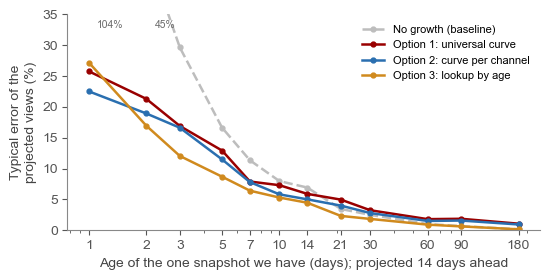

In [10]:
"""Figure: typical projection error by starting age."""
fig, ax = plt.subplots(figsize=(5.6, 2.9))
styles = {"no growth": [GRAY, "--"], "option 1": [RED, "-"], "option 2": ["#2A6FB0", "-"], "option 3": ["#D08A1E", "-"]}
labels = {"no growth": "No growth (baseline)", "option 1": "Option 1: universal curve", "option 2": "Option 2: curve per channel",
          "option 3": "Option 3: lookup by age"}
for method in methods:
    ax.plot(df_projection_error.index, df_projection_error[method] * 100, color=styles[method][0], linestyle=styles[method][1],
            marker="o", markersize=3.5, linewidth=1.8, label=labels[method])
ax.set_xscale("log")
ax.set_xticks(df_projection_error.index)
ax.set_xticklabels([str(age) for age in df_projection_error.index])
ax.set_xlabel(f"Age of the one snapshot we have (days); projected {HORIZON} days ahead")
ax.set_ylabel("Typical error of the\nprojected views (%)")
ax.set_ylim(0, 35)
for start_age, value in (df_projection_error["no growth"] * 100).items():
    if value > 35:
        ax.annotate(f"{value:.0f}%", (start_age, 35), textcoords="offset points", xytext=(6, -10), fontsize=7.5, color=MUTED)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/age_projection_error.png", dpi=200)
plt.show()

## Metric 2: what the traits add, within channel

In [11]:
def ridge_predict(df_train_X, y_train, df_test_X):
    keep = df_train_X.columns[df_train_X.std() > 0]
    scaler = StandardScaler().fit(df_train_X[keep])
    model = RidgeCV(alphas=ALPHAS).fit(scaler.transform(df_train_X[keep]), y_train)
    return model.predict(scaler.transform(df_test_X[keep]))


def cv_r2(df_X, y, rows):
    """Cross-validated R2 (5 folds x N_REPEATS, ridge) on the given rows."""
    scores = []
    for repeat in range(N_REPEATS):
        predicted = np.zeros(len(rows))
        for train, test in KFold(N_FOLDS, shuffle=True, random_state=repeat).split(rows):
            predicted[test] = ridge_predict(df_X.iloc[rows[train]], np.asarray(y)[rows[train]], df_X.iloc[rows[test]])
        actual = np.asarray(y)[rows]
        scores.append(1 - ((actual - predicted) ** 2).sum() / ((actual - actual.mean()) ** 2).sum())
    return np.mean(scores)


def trait_signal(y, rows):
    """CV R2 without traits, with traits, and with traits shuffled within channel (mean of N_SHUFFLES)."""
    r2_base = cv_r2(base_columns, y, rows)
    r2_full = cv_r2(pd.concat([X_traits, base_columns], axis=1), y, rows)
    shuffled = []
    for shuffle in range(N_SHUFFLES):
        X_shuffled = X_traits.to_numpy().copy()
        for channel_rows in df_videos.iloc[rows].groupby("channel_id").indices.values():
            positions = rows[channel_rows]
            X_shuffled[positions] = X_shuffled[rng.permutation(positions)]
        shuffled.append(cv_r2(pd.concat([pd.DataFrame(X_shuffled, columns=trait_columns), base_columns], axis=1), y, rows))
    return {"n": len(rows), "r2_base": r2_base, "r2_full": r2_full, "r2_shuffled": np.mean(shuffled),
            "gain_pps": (r2_full - r2_base) * 100, "shuffled_gain_pps": (np.mean(shuffled) - r2_base) * 100}


"""Age-free targets on the Nov 12 snapshot, both at the day-30 reference:
option 1: log views - G(age) + G(30); option 2: log views - k_channel x [G(age) - G(30)]."""
curve_gap = G(df_videos["age_days"]) - G(np.full(len(df_videos), REF_AGE))
df_videos["y_option1"] = df_videos["lv"] - curve_gap
df_videos["y_option2"] = df_videos["lv"] - df_videos["channel_id"].map(channel_k).fillna(1.0) * curve_gap
signal_rows = [{"option": "Option 1", **trait_signal(df_videos["y_option1"], all_rows)},
               {"option": "Option 2", **trait_signal(df_videos["y_option2"], all_rows)}]
for age in FIXED_AGES:
    rows = np.flatnonzero(df_videos[f"lv_{age}"].notna())
    signal_rows.append({"option": f"Option 3: day {age}", **trait_signal(df_videos[f"lv_{age}"], rows)})
df_signal = pd.DataFrame(signal_rows)
df_signal.to_csv(f"{ANALYSIS_DIR}/age_options_trait_signal.csv", index=False)
print(df_signal.round(4).to_string(index=False))

          option    n  r2_base  r2_full  r2_shuffled  gain_pps  shuffled_gain_pps
        Option 1 3021   0.7844   0.7868       0.7769    0.2398            -0.7579
        Option 2 3021   0.7824   0.7850       0.7750    0.2567            -0.7435
 Option 3: day 3  734   0.7797   0.7703       0.7448   -0.9338            -3.4864
 Option 3: day 7  856   0.7450   0.7222       0.7110   -2.2813            -3.4015
Option 3: day 14  890   0.7424   0.7218       0.7078   -2.0598            -3.4614
Option 3: day 30  733   0.7144   0.6973       0.6715   -1.7078            -4.2883
Option 3: day 60  380   0.7799   0.7389       0.7150   -4.1048            -6.4925
Option 3: day 90  190   0.8208   0.7364       0.6903   -8.4443           -13.0477


## Trait effects

In [12]:
def ols_within_channel(y):
    X = sm.add_constant(pd.concat([X_traits, df_meta, df_channel], axis=1), has_constant="add")
    groups = pd.factorize(df_videos["channel_id"])[0]
    return sm.OLS(np.asarray(y), X).fit(cov_type="cluster", cov_kwds={"groups": groups})


fit_option1 = ols_within_channel(df_videos["y_option1"])
fit_option2 = ols_within_channel(df_videos["y_option2"])
df_coef = pd.DataFrame({"option1": fit_option1.params[trait_columns], "option1_se": fit_option1.bse[trait_columns],
                        "option1_t": fit_option1.tvalues[trait_columns], "option2": fit_option2.params[trait_columns]})
for age in FIXED_AGES:
    rows = np.flatnonzero(df_videos[f"lv_{age}"].notna())
    X = pd.concat([X_traits, df_meta, df_channel], axis=1).iloc[rows]
    X = X.loc[:, X.std() > 0]
    scaler = StandardScaler().fit(X)
    model = RidgeCV(alphas=ALPHAS).fit(scaler.transform(X), df_videos[f"lv_{age}"].iloc[rows])
    df_coef[f"day{age}"] = pd.Series(model.coef_ / scaler.scale_, index=X.columns).reindex(trait_columns)
df_coef.to_csv(f"{ANALYSIS_DIR}/age_options_coefficients.csv")
top_option1 = df_coef["option1_t"].abs().sort_values(ascending=False).index[:10].tolist()
top_option2 = df_coef["option2"].abs().sort_values(ascending=False).index[:10].tolist()
print("Option 1 vs option 2 coefficient correlation:", round(df_coef["option1"].corr(df_coef["option2"]), 3),
      "| top-10 overlap:", len([trait for trait in top_option1 if trait in top_option2]))
print(df_coef[[f"day{age}" for age in FIXED_AGES] + ["option1"]].corr()["option1"].round(2))

Option 1 vs option 2 coefficient correlation: 1.0 | top-10 overlap: 8
day3       0.26
day7       0.36
day14      0.45
day30      0.54
day60      0.25
day90      0.07
option1    1.00
Name: option1, dtype: float64


## Figures for the deck

Worked example: 200,000 views at day 45 -> 191,020 at day 30


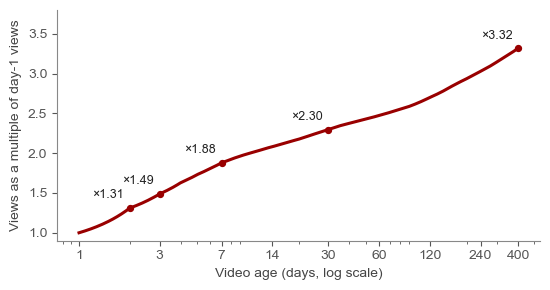

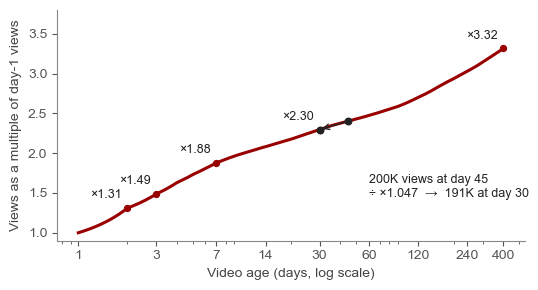

In [13]:
"""Universal curve, plain and with a worked example (200K views at day 45 moved to day 30)."""
ages_fine = np.exp(np.linspace(0, np.log(400), 300))
example_age, example_views = 45, 200_000
example_norm = np.exp(np.log1p(example_views) - G([example_age])[0] + G([REF_AGE])[0])
print(f"Worked example: {example_views:,} views at day {example_age} -> {example_norm:,.0f} at day {REF_AGE}")
for figure_name, with_example in [["age_universal_curve", False], ["age_universal_curve_example", True]]:
    fig, ax = plt.subplots(figsize=(5.6, 3.0))
    ax.plot(ages_fine, np.exp(G(ages_fine)), color=RED, linewidth=2.2)
    labeled = df_curve[df_curve["age_days"].isin([2, 3, 7, 30, 400])]
    ax.scatter(labeled["age_days"], labeled["multiple_of_day1"], color=RED, s=18, zorder=3)
    for _, row in labeled.iterrows():
        ax.annotate(f"×{row['multiple_of_day1']:.2f}", (row["age_days"], row["multiple_of_day1"]), textcoords="offset points",
                    xytext=(-4, 7), fontsize=9, color=DARK, ha="right")
    if with_example:
        y_example, y_ref = np.exp(G([example_age])[0]), np.exp(G([REF_AGE])[0])
        ax.scatter([example_age, REF_AGE], [y_example, y_ref], color=DARK, s=22, zorder=4)
        ax.annotate("", xy=(REF_AGE, y_ref), xytext=(example_age, y_example), arrowprops={"arrowstyle": "->", "color": DARK})
        ax.text(60, 1.45, f"{example_views / 1e3:.0f}K views at day {example_age}\n÷ ×{y_example / y_ref:.3f}  →  "
                f"{example_norm / 1e3:.0f}K at day {REF_AGE}", fontsize=9, color=DARK)
    ax.set_xscale("log")
    ax.set_xticks([1, 3, 7, 14, 30, 60, 120, 240, 400])
    ax.set_xticklabels(["1", "3", "7", "14", "30", "60", "120", "240", "400"])
    ax.set_ylim(0.9, 3.8)
    ax.set_xlabel("Video age (days, log scale)")
    ax.set_ylabel("Views as a multiple of day-1 views")
    fig.tight_layout()
    fig.savefig(f"{FIG_DIR}/{figure_name}.png", dpi=200)
    plt.show()

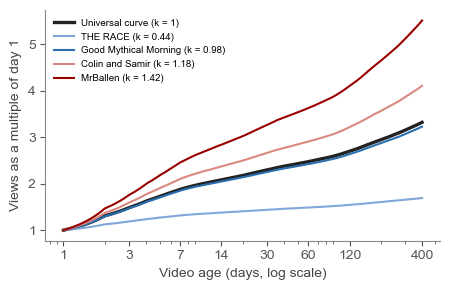

In [14]:
"""Option 2: example channel curves (slowest, fastest and two in between, among channels with 200+ young pairs)."""
df_k_example = df_k[df_k["young_pairs"] >= 200].reset_index(drop=True)
picks = [0, len(df_k_example) // 3, 2 * len(df_k_example) // 3, len(df_k_example) - 1]
fig, ax = plt.subplots(figsize=(4.6, 3.0))
ax.plot(ages_fine, np.exp(G(ages_fine)), color=DARK, linewidth=2.4, label="Universal curve (k = 1)")
for position, color in zip(picks, ["#7FA7D9", "#2A6FB0", "#D9897F", RED]):
    row = df_k_example.iloc[position]
    ax.plot(ages_fine, np.exp(row["k"] * G(ages_fine)), color=color, linewidth=1.5, label=f"{row['channel']} (k = {row['k']:.2f})")
ax.set_xscale("log")
ax.set_xticks([1, 3, 7, 14, 30, 60, 120, 400])
ax.set_xticklabels(["1", "3", "7", "14", "30", "60", "120", "400"])
ax.set_xlabel("Video age (days, log scale)")
ax.set_ylabel("Views as a multiple of day 1")
ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/age_option2_channel_curves.png", dpi=200)
plt.show()

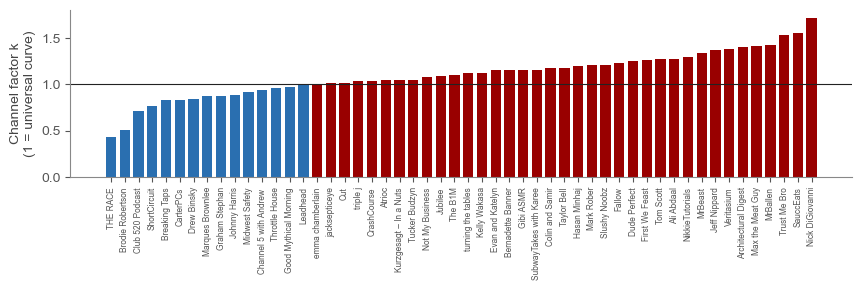

In [15]:
"""Option 2: every channel's factor k (sorted)."""
fig, ax = plt.subplots(figsize=(8.8, 3.0))
colors = [RED if k > 1 else "#2A6FB0" for k in df_k["k"]]
ax.bar(range(len(df_k)), df_k["k"], color=colors, width=0.75)
ax.axhline(1, color=DARK, linewidth=0.8)
ax.set_xticks(range(len(df_k)))
ax.set_xticklabels(df_k["channel"].str.slice(0, 22), rotation=90, fontsize=6)
ax.set_ylabel("Channel factor k\n(1 = universal curve)")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/age_option2_k_by_channel.png", dpi=220)
plt.show()

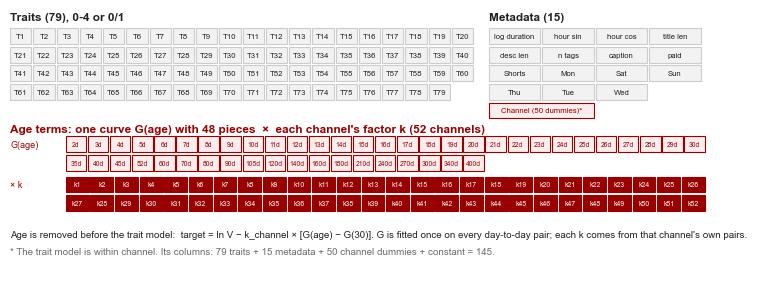

In [16]:
"""Option 2's predictors: what the trait model sees, and the age terms that remove age first (red = age and what it
interacts with). Age enters as one curve shape G(age), multiplied by each channel's own factor k."""
fig, ax = plt.subplots(figsize=(9.0, 3.4))
ax.set_xlim(0, 30)
ax.set_ylim(0, 12)
ax.axis("off")


def chip(x, y, label, face, edge, text_color, width=0.92, size=5.6):
    ax.add_patch(plt.Rectangle((x, y), width, 0.72, facecolor=face, edgecolor=edge, linewidth=0.8))
    ax.text(x + width / 2, y + 0.36, label, ha="center", va="center", fontsize=size, color=text_color)


ax.text(0, 11.5, f"Traits ({len(trait_columns)}), 0-4 or 0/1", fontsize=8.5, color=DARK, weight="bold")
for trait_number in range(len(trait_columns)):
    chip((trait_number % 20) * 1.0, 10.4 - (trait_number // 20) * 0.85, f"T{trait_number + 1}", "#F2F2F2", "#CCCCCC", DARK)
ax.text(20.6, 11.5, f"Metadata ({df_meta.shape[1]})", fontsize=8.5, color=DARK, weight="bold")
meta_labels = ["log duration", "hour sin", "hour cos", "title len", "desc len", "n tags", "caption", "paid", "Shorts",
               "Mon", "Sat", "Sun", "Thu", "Tue", "Wed"]
for meta_number, label in enumerate(meta_labels):
    chip(20.6 + (meta_number % 4) * 2.3, 10.4 - (meta_number // 4) * 0.85, label, "#F2F2F2", "#CCCCCC", DARK, width=2.2)
chip(20.6, 10.4 - 4 * 0.85, f"Channel ({df_channel.shape[1]} dummies)*", "#FBEDED", RED, RED, width=4.5)

ax.text(0, 6.35, f"Age terms: one curve G(age) with {len(KNOTS) - 1} pieces  ×  each channel's factor k ({len(channel_k)} channels)",
        fontsize=8.5, color=RED, weight="bold")
ax.text(0, 5.45 + 0.36, "G(age)", fontsize=6.5, color=RED, va="center")
curve_pieces = [f"{knot:g}d" for knot in KNOTS[1:]]
for piece_number, label in enumerate(curve_pieces):
    row, column = piece_number // 29, piece_number % 29
    chip(2.4 + column * 0.95, 5.45 - row * 0.85, label, "#FBEDED", RED, RED, width=0.88, size=4.8)
ax.text(0, 3.6 + 0.36, "× k", fontsize=6.5, color=RED, va="center")
for channel_number in range(len(channel_k)):
    row, column = channel_number // 26, channel_number % 26
    chip(2.4 + column * 1.06, 3.6 - row * 0.85, f"k{channel_number + 1}", RED, RED, "white", width=0.98, size=5)
ax.text(0, 1.55, "Age is removed before the trait model:  target = ln V − k_channel × [G(age) − G(30)]. G is fitted once on every "
        "day-to-day pair; each k comes from that channel's own pairs.", fontsize=7, color=DARK)
ax.text(0, 0.75, f"* The trait model is within channel. Its columns: {len(trait_columns)} traits + {df_meta.shape[1]} metadata + "
        f"{df_channel.shape[1]} channel dummies + constant = {len(trait_columns) + df_meta.shape[1] + df_channel.shape[1] + 1}.",
        fontsize=7, color=MUTED)
fig.savefig(f"{FIG_DIR}/age_option2_predictors.png", dpi=220, bbox_inches="tight")
plt.show()

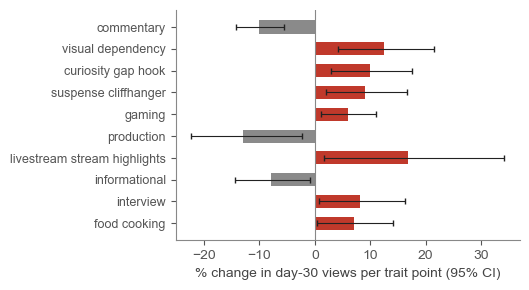

In [17]:
"""Option 1: top 10 traits by |t|, % change in day-30 views per trait point with 95% CI."""
df_top = df_coef.loc[top_option1]
effect = (np.exp(df_top["option1"]) - 1) * 100
low = (np.exp(df_top["option1"] - 1.96 * df_top["option1_se"]) - 1) * 100
high = (np.exp(df_top["option1"] + 1.96 * df_top["option1_se"]) - 1) * 100
positions = np.arange(len(df_top))[::-1]
fig, ax = plt.subplots(figsize=(5.4, 3.0))
ax.barh(positions, effect, color=[BAR if value > 0 else "#8A8A8A" for value in effect], height=0.6)
ax.errorbar(effect, positions, xerr=[effect - low, high - effect], fmt="none", ecolor=DARK, elinewidth=0.8, capsize=2)
ax.set_yticks(positions)
ax.set_yticklabels([name.replace("_", " ") for name in df_top.index], fontsize=9)
ax.axvline(0, color="#888888", linewidth=0.8)
ax.set_xlabel("% change in day-30 views per trait point (95% CI)")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/age_option1_top_traits.png", dpi=200)
plt.show()

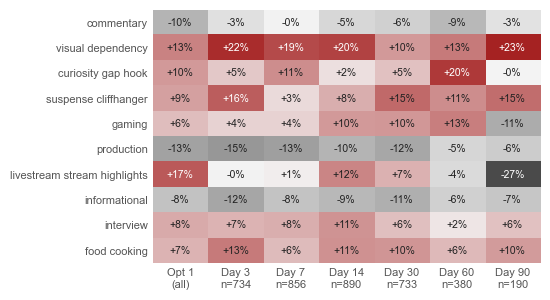

In [18]:
"""Option 3 heatmap: option 1's top 10 traits at each fixed age (ridge, % per point)."""
heat_columns = ["option1"] + [f"day{age}" for age in FIXED_AGES]
df_heat = (np.exp(df_top[heat_columns]) - 1) * 100
colormap = LinearSegmentedColormap.from_list("diverging", ["#4A4A4A", "#F4F4F4", RED])
bound = np.abs(df_heat.to_numpy()).max()
fig, ax = plt.subplots(figsize=(5.6, 3.1))
ax.imshow(df_heat.to_numpy(), cmap=colormap, vmin=-bound, vmax=bound, aspect="auto")
for row_number in range(df_heat.shape[0]):
    for column_number in range(df_heat.shape[1]):
        value = df_heat.iloc[row_number, column_number]
        ax.text(column_number, row_number, f"{value:+.0f}%", ha="center", va="center", fontsize=7.5,
                color="white" if abs(value) > bound * 0.6 else DARK)
ax.set_xticks(range(len(heat_columns)))
ax.set_xticklabels(["Opt 1\n(all)"] + [f"Day {age}\nn={n}" for age, n in zip(FIXED_AGES, df_fixed_counts["tagged"])], fontsize=8)
ax.set_yticks(range(len(df_heat)))
ax.set_yticklabels([name.replace("_", " ") for name in df_heat.index], fontsize=8)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/age_option3_heatmap.png", dpi=200)
plt.show()

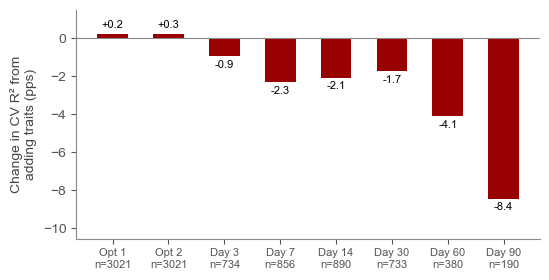

In [19]:
"""Metric 2 chart: change in CV R2 from adding the traits, in percentage points (shuffled control in the table above)."""
fig, ax = plt.subplots(figsize=(5.6, 2.9))
labels = ["Opt 1", "Opt 2"] + [f"Day {age}" for age in FIXED_AGES]
positions = np.arange(len(labels))
ax.bar(positions, df_signal["gain_pps"], width=0.55, color=RED)
for position, value in zip(positions, df_signal["gain_pps"]):
    ax.text(position, value + (0.2 if value >= 0 else -0.2), f"{value:+.1f}", ha="center", va="bottom" if value >= 0 else "top", fontsize=8)
ax.axhline(0, color="#888888", linewidth=0.8)
ax.set_xticks(positions)
ax.set_xticklabels([f"{label}\nn={n}" for label, n in zip(labels, df_signal["n"])], fontsize=8)
ax.set_ylabel("Change in CV R² from\nadding traits (pps)")
ax.set_ylim(min(df_signal["gain_pps"]) * 1.25, 1.5)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/age_options_trait_signal.png", dpi=200)
plt.show()